# OAE neural-network emulator

A workflow adapted from [Dagon et al. (2020)](https://ascmo.copernicus.org/articles/6/223/2020/):
**LHS → control simulations → SVD → neural networks → observational calibration → model validation**.

- `run_mode="pilot"`: use the existing **2000–2001 cases** to test SVD and NN training for CHL, PP and fCO2.
  Prepare the inputs with `prepare_pilot_2000_2001.ipynb`, using the model's Julia kernel.
- `run_mode="formal"`: use **100 completed six-parameter LHS controls** and matched observations for calibration.

Section 2 generates the formal 100-member LHS design. The pilot keeps its original case parameters in a
separate table. Pilot training does not search for an optimal six-parameter model configuration.

## 1. Settings

Choose `"pilot"` for the existing 2000–2001 cases or `"formal"` for the planned 1990–2010 ensemble.
Pilot dates must match the preparation notebook. Both modes search all 121 two-hidden-layer
architectures with 5–15 nodes per layer, then evaluate the leading `top_k=5` architectures
across `n_repeats=100` random training/validation splits.

The default search trains 622 networks per target: 121 initial fits, 500 resampling fits
and one final fit. Pilot mode keeps its shorter epoch limit and skips observational calibration.


In [12]:
from pathlib import Path
from itertools import product
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution
from scipy.stats import qmc
import scipy
from IPython.display import display

run_mode = "pilot"  # "pilot" or "formal"
assert run_mode in ("pilot", "formal")
is_pilot = run_mode == "pilot"
pilot_targets = ("CHL", "PP", "fCO2")
pilot_period = ("2000-01-01", "2001-12-31")
seed = 42
n_samples = 100
n_modes = 3
project_dir = Path.cwd()
if (project_dir / "ML4OAE" / "oae_nn_emulator.ipynb").is_file():
    project_dir = project_dir / "ML4OAE"
if not (project_dir / "oae_nn_emulator.ipynb").is_file():
    raise FileNotFoundError("Start this notebook from ML4OAE or its parent, or set project_dir explicitly.")
data_dir = project_dir / "data"
pilot_file = data_dir / "pilot_2000-2001.nc"
period = pilot_period if is_pilot else ("1990-01-01", "2010-12-31")
output_dir = project_dir / "results" / ("pilot_2000-2001" if is_pilot else "formal")
architectures = list(product(range(5, 16), repeat=2))
l2_strength = 0.001  # Fixed coefficient used in the author's NN code.
top_k = 5
n_repeats = 100
assert 1 <= top_k <= len(architectures) and n_repeats >= 1, "Use a positive shortlist size and repeat count."
epochs = 100 if is_pilot else 500
patience = 15 if is_pilot else 50
targets = pilot_targets if is_pilot else ("CHL", "PP", "fCO2")
assert targets and len(set(targets)) == len(targets) and set(targets) <= {"CHL", "PP", "fCO2"}
units = {"CHL": "mg Chl m^-3", "PP": "mg C m^-2 day^-1", "fCO2": "uatm"}

parameters = pd.DataFrame([
    ("maximum_growth_rate", 0.4, 3.3, 2.09, "day^-1"),
    ("chlorophyll_ratio", 0.26, 2.62, 1.31, "mg Chl (mmol N)^-1"),
    ("iron_half_saturation", 0.02, 1.00, 0.20, "nM"),
    ("nitrate_half_saturation", 0.05, 3.00, 0.70, "uM"),
    ("light_half_saturation", 10.0, 100.0, 33.0, "W m^-2"),
    ("maximum_grazing_rate", 0.2, 1.8, 0.80, "day^-1"),
], columns=["name", "lower", "upper", "baseline", "unit"]).set_index("name")
lower, upper = parameters.lower.to_numpy(), parameters.upper.to_numpy()
output_dir.mkdir(parents=True, exist_ok=True)
print("Run mode:", run_mode, "| Target period:", period)
print("Pilot control cases: train and evaluate the emulator." if is_pilot
      else "Formal control ensemble: check matching and units.")
print("Architectures per target:", len(architectures))
print("Resampling:", top_k, "leading architectures x", n_repeats, "splits")
print("NN fits per target:", len(architectures) + top_k * n_repeats + 1)
print("Project directory:", project_dir.resolve())
display(parameters)

Run mode: pilot | Target period: ('2000-01-01', '2001-12-31')
Pilot control cases: train and evaluate the emulator.
Architectures per target: 121
Resampling: 5 leading architectures x 100 splits
NN fits per target: 622
Project directory: /nfs/roberts/pi/pi_ey239/qz334/ML4OAE


,lower,upper,baseline,unit
name,,,,
maximum_growth_rate,0.40,3.30,2.09,day^-1
chlorophyll_ratio,0.26,2.62,1.31,mg Chl (mmol N)^-1
iron_half_saturation,0.02,1.00,0.20,nM
nitrate_half_saturation,0.05,3.00,0.70,uM
light_half_saturation,10.00,100.00,33.00,W m^-2
maximum_grazing_rate,0.20,1.80,0.80,day^-1


## 2. Generate the 100-member LHS design

Generate a scrambled six-dimensional Latin hypercube with `seed=42` and `optimization="random-cd"`.
Each parameter range is divided into 100 equal intervals with one sample in each interval.
`random-cd` improves space filling by permuting coordinates while preserving these marginal strata.
The physical values are `lower + unit_sample * (upper - lower)`.

Save the design in `data/parameters.csv`, with IDs `sample_0001` through `sample_0100`.
`data/lhs_settings.json` records bounds, units, seed and SciPy version. Existing tables are reused.
The baseline control is separate from these 100 experiments.

Each design row requires a control-model simulation before formal training. Pilot cases use their own
parameter table and retain the values used in the completed simulations.

In [13]:
data_dir.mkdir(parents=True, exist_ok=True)
LHS_file = data_dir / "parameters.csv"
if LHS_file.exists():
    lhs_table = pd.read_csv(LHS_file, dtype={"sample_id": str})
    print("Reusing existing parameter table without changing its rows:", LHS_file)
else:
    sampler = qmc.LatinHypercube(d=6, scramble=True, optimization="random-cd", seed=seed)
    unit_samples = sampler.random(n=n_samples)
    lhs_table = pd.DataFrame(qmc.scale(unit_samples, lower, upper), columns=parameters.index)
    lhs_table.insert(0, "sample_id", [f"sample_{i + 1:04d}" for i in range(n_samples)])
    with LHS_file.open("x") as handle:
        lhs_table.to_csv(handle, index=False)
    lhs_settings = dict(n_samples=n_samples, seed=seed, method="scipy.stats.qmc.LatinHypercube",
        scramble=True, optimization="random-cd", scipy_version=scipy.__version__,
        parameters=parameters.reset_index().to_dict(orient="records"))
    (data_dir / "lhs_settings.json").write_text(json.dumps(lhs_settings, indent=2))
    print("Exported 100 proposed control parameter sets:", LHS_file)

assert len(lhs_table) == n_samples and lhs_table.sample_id.notna().all() and lhs_table.sample_id.is_unique
design = (lhs_table[parameters.index].to_numpy(float) - lower) / (upper - lower)
assert np.isfinite(design).all() and np.all((design >= 0) & (design <= 1)), "Check parameter units and bounds."
print("Parameter sets:", len(lhs_table), "| Parameters:", len(parameters))
display(lhs_table.head())

Reusing existing parameter table without changing its rows: /nfs/roberts/pi/pi_ey239/qz334/ML4OAE/data/parameters.csv
Parameter sets: 100 | Parameters: 6


,sample_id,maximum_growth_rate,chlorophyll_ratio,iron_half_saturation,nitrate_half_saturation,light_half_saturation,maximum_grazing_rate
0,sample_0001,2.146427,0.320442,0.570186,0.473804,74.228754,1.631928
1,sample_0002,1.398846,0.383049,0.776067,1.195669,93.423218,1.065172
2,sample_0003,0.845175,1.292980,0.123455,1.735064,18.500874,0.714677
3,sample_0004,0.553550,1.539123,0.479772,2.606041,15.426372,1.488330
4,sample_0005,2.175555,1.341007,0.875510,1.652740,92.661139,1.408828


## 3. Read the control ensemble

**Pilot:** `data/pilot_2000-2001.nc` contains a period-mean field for each independent case, six model parameters
and native cell areas. The preparation notebook exports CHL and PP and calculates control fCO2 from
saved DIC1, Alk1, temperature and salinity. At least four cases are required for the training/validation/test split.
Continuation folders, years and MPI ranks belong to the same parameter case.

**Formal:** `data/parameters.csv` contains the 100 parameter sets used by the control ensemble.
`data/prepared_data.npz` contains control fields, observation means, annual observations and cell areas.
Rows are matched by `sample_id`. Model and observation features must match in grid, depth, units and period.

In [14]:
if is_pilot:
    from netCDF4 import Dataset

    if not pilot_file.is_file():
        raise FileNotFoundError(f"First run prepare_pilot_2000_2001.ipynb with the Julia kernel to create {pilot_file}")
    with Dataset(pilot_file) as archive:
        recorded_period = (archive.getncattr("period_start"), archive.getncattr("period_end"))
        assert recorded_period == period, f"Export period {recorded_period} does not match settings {period}."
        table = pd.DataFrame({"sample_id": np.asarray(archive["sample_id"][:]).astype(str)})
        for name in parameters.index:
            variable = archive[name]
            assert variable.dimensions == ("sample",) and variable.getncattr("units") == parameters.loc[name, "unit"], f"Check {name} dimensions and units."
            table[name] = np.ma.filled(variable[:], np.nan)
        controls, areas = {}, {}
        for t in targets:
            assert t in archive.variables, f"Missing {t}: export the actual diagnostic or remove it from pilot_targets."
            field = archive[t]
            assert field.dimensions == ("sample", "feature"), "Expected (sample, feature) field order."
            assert field.getncattr("units") == units[t], f"Check {t} units before using the export."
            controls[t] = np.ma.filled(field[:], np.nan).astype(float)
            areas[t] = np.ma.filled(archive["cell_area"][:], np.nan).astype(float)
    obs_mean, obs_years = {}, {}
    print("Loaded actual pilot cases:")
    display(table)
else:
    table = pd.read_csv(data_dir / "parameters.csv", dtype={"sample_id": str})
    with np.load(data_dir / "prepared_data.npz", allow_pickle=False) as archive:
        ids = archive["sample_id"].astype(str)
        assert table.sample_id.is_unique and len(set(ids)) == len(ids) == len(table)
        assert set(ids) == set(table.sample_id), "CSV and simulation IDs must match exactly."
        lookup = {sample_id: i for i, sample_id in enumerate(ids)}
        order = [lookup[sample_id] for sample_id in table.sample_id]
        controls = {t: archive[t][order] for t in targets}
        obs_mean = {t: archive[f"{t}_obs_mean"] for t in targets}
        obs_years = {t: archive[f"{t}_obs_years"] for t in targets}
        areas = {t: archive[f"{t}_area"] for t in targets}

x = (table[parameters.index].to_numpy(float) - lower) / (upper - lower)
assert table.sample_id.notna().all() and table.sample_id.is_unique, "Case IDs must be unique."
assert np.isfinite(x).all() and np.all((x >= 0) & (x <= 1)), "Check actual parameters, physical units and bounds."
assert (len(x) >= 4 if is_pilot else len(x) == n_samples), "Pilot needs at least 4 distinct cases; formal needs 100."
varying = list(parameters.index[np.ptp(x, axis=0) > 1e-12])
print("Parameters that vary across these cases:", varying)
if is_pilot:
    print("Parameters that remain fixed are not constrained by this ensemble.")
assert len(np.unique(x, axis=0)) == len(x), "Each row must be a distinct parameter experiment."
for t in targets:
    assert controls[t].ndim == 2 and controls[t].shape[0] == len(x)
    g = controls[t].shape[1]
    assert areas[t].shape == (g,)
    if not is_pilot:
        assert obs_mean[t].shape == (g,)
        assert obs_years[t].ndim == 2 and obs_years[t].shape[0] >= 2 and obs_years[t].shape[1] == g
    assert np.isfinite(areas[t]).all() and np.all(areas[t] > 0)
print("Control members:", len(x), "| Features:", {t: controls[t].shape[1] for t in targets})

Loaded actual pilot cases:


,sample_id,maximum_growth_rate,chlorophyll_ratio,iron_half_saturation,nitrate_half_saturation,light_half_saturation,maximum_grazing_rate
0,reference,2.09088,1.310,0.2,0.7,33.0,0.800064
1,chl30_kfe50,2.09088,0.393,0.1,0.7,33.0,0.800064
2,chl30_growth_plus25,2.61360,0.393,0.2,0.7,33.0,0.800064
3,chl30_kfe50_growth_plus25,2.61360,0.393,0.1,0.7,33.0,0.800064


Parameters that vary across these cases: ['maximum_growth_rate', 'chlorophyll_ratio', 'iron_half_saturation']
Parameters that remain fixed are not constrained by this ensemble.
Control members: 4 | Features: {'CHL': 40569, 'PP': 40569, 'fCO2': 40569}


## 4. Split cases and define the SVD

Split parameter cases into 60% training, 20% validation and 20% testing.
Fit the mean and area-weighted SVD to training cases. The NN predicts the SVD U scores:
`U = ((field - model_mean) * sqrt_area) @ V.T / singular_values`.
Use the same transform for held-out cases and observations.

Pilot mode retains fewer modes when the training matrix has lower rank; two training cases can support
at most one centered mode. The NN output dimension follows the retained rank.

In [15]:
order = np.random.default_rng(seed).permutation(len(x))
a, b = int(.6 * len(x)), int(.8 * len(x))
train, val, test = order[:a], order[a:b], order[b:]

def fit_svd(y, area, available):
    mask = available & np.isfinite(y).all(axis=0)
    assert mask.any() and len(y) >= 2, "Need common finite cells and at least two training cases."
    mean = y[:, mask].mean(axis=0)
    weight = np.sqrt(area[mask] / area[mask].mean())
    _, s, vt = np.linalg.svd((y[:, mask] - mean) * weight, full_matrices=False)
    rank = int(np.count_nonzero(s > s[0] * 1e-10))
    modes = min(n_modes, len(y) - 1, rank) if is_pilot else n_modes
    assert modes > 0 and rank >= modes, "Target has too few responsive SVD modes."
    return dict(mask=mask, mean=mean, weight=weight, s=s[:modes], vt=vt[:modes], variance=s**2 / np.sum(s**2))

def project(y, basis):
    matched = np.atleast_2d(y)[:, basis["mask"]]
    assert np.isfinite(matched).all(), "Missing values on the fitted support: prepare a consistent mask."
    return ((matched - basis["mean"]) * basis["weight"]) @ basis["vt"].T / basis["s"]

def reconstruct(scores, basis):
    return (scores * basis["s"]) @ basis["vt"] / basis["weight"] + basis["mean"]

## 5. Define the neural network

Two hidden layers use ReLU and tanh activations, followed by a linear output layer.
Training uses RMSprop (learning rate 0.005), batch size 30, L2 regularization and validation early stopping.
Output scores are standardized using training statistics and converted back for prediction.

The fixed Keras L2 coefficient (0.001) and formal epoch limit (500) follow the
[author's NN code](https://github.com/katiedagon/CLM5_ParameterUncertainty/blob/main/NN/NN_test.py).
Pilot mode uses a shorter 100-epoch limit. Early stopping monitors validation MSE with
patience of 15 epochs in pilot mode and 50 in formal mode, restoring the best weights.
These stopping settings operate on the standardized scores used here.


In [16]:
from tensorflow import keras

def train_nn(x_train, z_train, x_val, z_val, widths, l2_strength, seed):
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    center, scale = z_train.mean(axis=0), z_train.std(axis=0)
    assert np.all(scale > 0), "Training scores must have nonzero variability."
    assert len(widths) == 2, "The architecture search uses two hidden layers."
    model = keras.Sequential([
        keras.Input(shape=(6,)),
        keras.layers.Dense(widths[0], activation="relu", kernel_regularizer=keras.regularizers.l2(l2_strength)),
        keras.layers.Dense(widths[1], activation="tanh", kernel_regularizer=keras.regularizers.l2(l2_strength)),
        keras.layers.Dense(z_train.shape[1]),
    ])
    model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=.005), loss="mse", metrics=["mse"])
    stop = keras.callbacks.EarlyStopping(monitor="val_mse", patience=patience, restore_best_weights=True)
    model.fit(x_train, (z_train - center) / scale,
              validation_data=(x_val, (z_val - center) / scale),
              epochs=epochs, batch_size=30, callbacks=[stop], verbose=0)
    return dict(model=model, center=center, scale=scale,
                widths=tuple(widths), l2_strength=float(l2_strength))

def predict(network, x_new):
    values = network["model"](np.asarray(x_new, dtype="float32"), training=False).numpy()
    return values * network["scale"] + network["center"]


## 6. Hyperparameter tuning and model training

For each target (CHL, PP and fCO2), compare all 121 two-hidden-layer architectures:
5–15 nodes in the first layer and independently 5–15 nodes in the second layer.
The L2 coefficient and other training settings remain fixed. Candidates use the same
initialization seed. Rank the initial fits by validation mean squared error (MSE).

Following Dagon et al. (2020), evaluate the leading five architectures over 100 random
training/validation splits. The held-out test cases never enter these splits. Each split
refits its own SVD and score scaling. Report validation MSE and squared Pearson correlation
for each retained mode, including their variability across splits.

The article describes selection using predictive skill and stability without specifying
a single ranking formula. Here, select the lowest mean resampled validation MSE, using
its standard deviation to break ties. Correlations are reported for inspection.
Retrain the selected architecture on the original training split, with early stopping
on the original validation split.

`tuning.csv` records the architecture comparison and selected row. `tuning_resamples.csv`
records individual resampling results. With four pilot cases, each validation split has
only one case, so correlations are undefined. Repeating these small splits does not add
independent cases; the architecture selection remains preliminary.


In [17]:
def mode_r2(actual, predicted):
    values = np.full(actual.shape[1], np.nan)
    if len(actual) < 2:
        return values
    for k in range(actual.shape[1]):
        if np.std(actual[:, k]) > 1e-12 and np.std(predicted[:, k]) > 1e-12:
            values[k] = np.corrcoef(actual[:, k], predicted[:, k])[0, 1] ** 2
    return values

fitted, tuning_rows, resampling_rows = {}, [], []
pool = np.concatenate((train, val))
for t in targets:
    available = np.ones(controls[t].shape[1], dtype=bool) if is_pilot else np.isfinite(obs_mean[t]) & np.isfinite(obs_years[t]).all(axis=0)
    basis = fit_svd(controls[t][train], areas[t], available)
    z_train, z_val = project(controls[t][train], basis), project(controls[t][val], basis)
    print(t, "retained SVD modes:", len(basis["s"]))
    trials = []
    for i, widths in enumerate(architectures, start=1):
        network = train_nn(x[train], z_train, x[val], z_val, widths, l2_strength, seed)
        predicted = predict(network, x[val])
        row = dict(widths=widths, l2_strength=l2_strength,
                   validation_mse=float(np.mean((predicted - z_val)**2)), selected=False)
        row.update({f"validation_r2_PC{k + 1}": value
                    for k, value in enumerate(mode_r2(z_val, predicted))})
        trials.append(row)
        if i % 20 == 0 or i == len(architectures):
            print(f"{t}: initial search {i}/{len(architectures)}")
    leaders = sorted(trials, key=lambda row: row["validation_mse"])[:top_k]
    for leader_index, row in enumerate(leaders, start=1):
        errors, correlations = [], []
        print(f"{t}: resampling architecture {leader_index}/{len(leaders)} {row['widths']}")
        for repeat in range(n_repeats):
            shuffled = np.random.default_rng(seed + 1000 + repeat).permutation(pool)
            tr, va = shuffled[:len(train)], shuffled[len(train):]
            rb = fit_svd(controls[t][tr], areas[t], available)
            ztr, zva = project(controls[t][tr], rb), project(controls[t][va], rb)
            nn = train_nn(x[tr], ztr, x[va], zva, row["widths"], l2_strength,
                          seed + 2000 + repeat)
            predicted = predict(nn, x[va])
            mse = float(np.mean((predicted - zva)**2))
            r2 = mode_r2(zva, predicted)
            errors.append(mse)
            correlations.append(r2)
            result = dict(target=t, widths=row["widths"], repeat=repeat + 1, validation_mse=mse)
            result.update({f"validation_r2_PC{k + 1}": value for k, value in enumerate(r2)})
            resampling_rows.append(result)
            if (repeat + 1) % 25 == 0 or repeat + 1 == n_repeats:
                print(f"{t} {row['widths']}: resampling {repeat + 1}/{n_repeats}")
        row["repeat_mean"], row["repeat_std"] = float(np.mean(errors)), float(np.std(errors))
        correlations = np.asarray(correlations)
        for k in range(correlations.shape[1]):
            valid = correlations[:, k][np.isfinite(correlations[:, k])]
            row[f"repeat_r2_PC{k + 1}_mean"] = float(valid.mean()) if len(valid) else np.nan
            row[f"repeat_r2_PC{k + 1}_std"] = float(valid.std()) if len(valid) else np.nan
    best = min(leaders, key=lambda row: (row["repeat_mean"], row["repeat_std"]))
    best["selected"] = True
    network = train_nn(x[train], z_train, x[val], z_val,
                       best["widths"], l2_strength, seed)
    fitted[t] = dict(basis=basis, network=network)
    tuning_rows.extend(dict(target=t, **row) for row in trials)
    pd.DataFrame(tuning_rows).to_csv(output_dir / "tuning.csv", index=False)
    pd.DataFrame(resampling_rows).to_csv(output_dir / "tuning_resamples.csv", index=False)
    print(t, "selected widths:", best["widths"], "| mean resampled MSE:", best["repeat_mean"])
tuning = pd.DataFrame(tuning_rows)


CHL retained SVD modes: 1
CHL: initial search 20/121
CHL: initial search 40/121
CHL: initial search 60/121
CHL: initial search 80/121
CHL: initial search 100/121
CHL: initial search 120/121
CHL: initial search 121/121
CHL: resampling architecture 1/5 (5, 14)
CHL (5, 14): resampling 25/100
CHL (5, 14): resampling 50/100
CHL (5, 14): resampling 75/100
CHL (5, 14): resampling 100/100
CHL: resampling architecture 2/5 (10, 15)
CHL (10, 15): resampling 25/100
CHL (10, 15): resampling 50/100
CHL (10, 15): resampling 75/100
CHL (10, 15): resampling 100/100
CHL: resampling architecture 3/5 (10, 11)
CHL (10, 11): resampling 25/100
CHL (10, 11): resampling 50/100
CHL (10, 11): resampling 75/100
CHL (10, 11): resampling 100/100
CHL: resampling architecture 4/5 (13, 9)
CHL (13, 9): resampling 25/100
CHL (13, 9): resampling 50/100
CHL (13, 9): resampling 75/100
CHL (13, 9): resampling 100/100
CHL: resampling architecture 5/5 (10, 14)
CHL (10, 14): resampling 25/100
CHL (10, 14): resampling 50/100
CH

In [31]:
import pandas as pd

tuning_file = "/nfs/roberts/pi/pi_ey239/qz334/ML4OAE/results/pilot_2000-2001/tuning.csv"
tuning = pd.read_csv(tuning_file)

display(tuning.loc[tuning["selected"], [
    "target", "widths", "l2_strength", "repeat_mean", "repeat_std"
]])

,target,widths,l2_strength,repeat_mean,repeat_std
9,CHL,"(5, 14)",0.001,0.121828,0.095100
130,PP,"(5, 14)",0.001,0.327421,0.155693
251,fCO2,"(5, 14)",0.001,0.292678,0.182701


## 7. Evaluate held-out cases

Compare predicted U scores with simulation scores and calculate area-weighted field RMSE.
`svd_rmse` measures compression error; `nn_rmse` combines compression and emulation error.
Retained variance indicates whether the selected SVD modes adequately represent the output fields.

With four pilot cases the split is 2/1/1. These metrics describe the small held-out sample;
the formal ensemble provides the broader test of emulator performance.

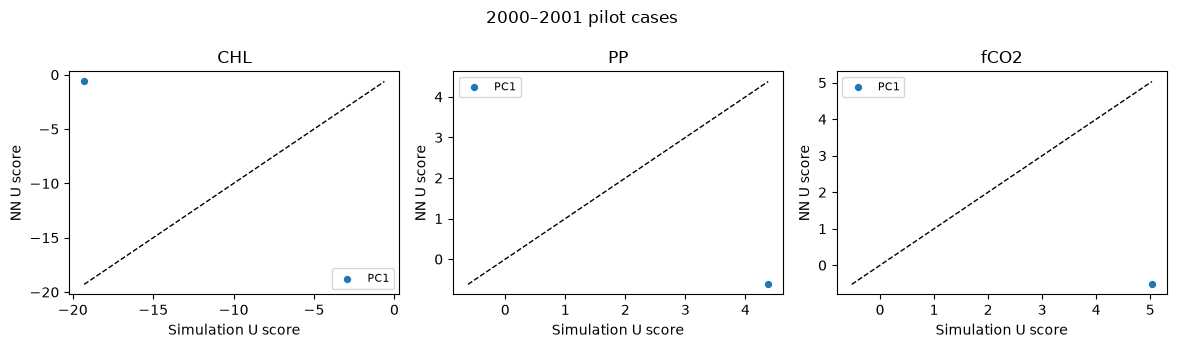

,target,modes,retained_variance,pc_mse,svd_rmse,nn_rmse,units
0,CHL,1,1.0,348.626629,0.472470,0.482483,mg Chl m^-3
1,PP,1,1.0,25.010545,36.857135,122.494738,mg C m^-2 day^-1
2,fCO2,1,1.0,30.881250,4.834301,14.415427,uatm


In [18]:
def weighted_rmse(actual, predicted, area):
    return float(np.sqrt(np.mean(np.average((actual - predicted)**2, axis=-1, weights=area))))

fig, axes = plt.subplots(1, len(targets), figsize=(4 * len(targets), 3.5), squeeze=False)
metrics = []
for ax, t in zip(axes.ravel(), targets):
    basis, network = fitted[t]["basis"], fitted[t]["network"]
    truth, pred = project(controls[t][test], basis), predict(network, x[test])
    for k in range(truth.shape[1]):
        ax.scatter(truth[:, k], pred[:, k], s=18, label=f"PC{k + 1}")
    lo, hi = min(truth.min(), pred.min()), max(truth.max(), pred.max())
    ax.plot([lo, hi], [lo, hi], "k--", linewidth=1)
    ax.set(title=t, xlabel="Simulation U score", ylabel="NN U score")
    ax.legend(fontsize=8)
    mask = basis["mask"]
    metrics.append(dict(target=t, modes=len(basis["s"]), retained_variance=basis["variance"][:len(basis["s"])].sum(),
        pc_mse=float(np.mean((truth - pred)**2)),
        svd_rmse=weighted_rmse(controls[t][test][:, mask], reconstruct(truth, basis), areas[t][mask]),
        nn_rmse=weighted_rmse(controls[t][test][:, mask], reconstruct(pred, basis), areas[t][mask]), units=units[t]))
fig.suptitle("2000–2001 pilot cases" if is_pilot else "Held-out control simulations")
fig.tight_layout()
fig.savefig(output_dir / "test_predictions.png", dpi=160)
plt.show()
metrics = pd.DataFrame(metrics)
metrics.to_csv(output_dir / "test_metrics.csv", index=False)
display(metrics)

## 7a. Plot pilot SVD spatial modes

Map each retained mode on the native pilot grid. The plotted pattern is
`singular_value * spatial_vector / area_weight`: the physical field change for
an increase of one unit in the corresponding U score. Each case is reconstructed
as the training mean plus the sum of its scores multiplied by these patterns.

Colors show opposite contributions to the spatial pattern; they do not indicate
model bias. The sign of a mode is arbitrary. Percentages refer to training variance,
not prediction accuracy. With two centered training cases, the single retained mode
follows their difference. These maps use native grid-point locations without regridding.


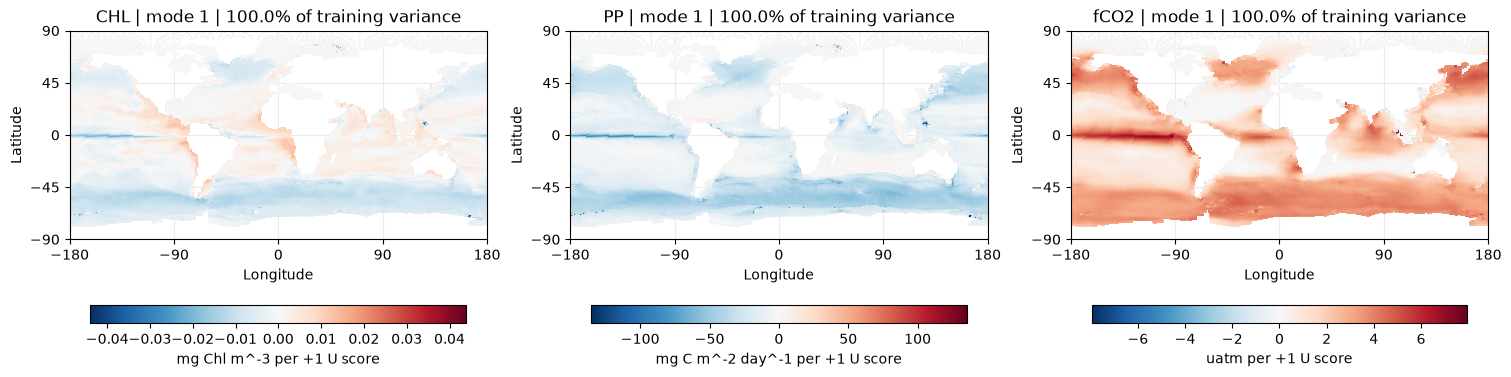

Saved to: /nfs/roberts/pi/pi_ey239/qz334/ML4OAE/results/pilot_2000-2001/svd_spatial_modes.png


In [25]:
if is_pilot:
    from netCDF4 import Dataset

    with Dataset(pilot_file) as archive:
        longitude = np.ma.filled(archive["longitude"][:], np.nan).astype(float)
        latitude = np.ma.filled(archive["latitude"][:], np.nan).astype(float)
    longitude = (longitude + 180) % 360 - 180

    n_rows = max(len(fitted[t]["basis"]["s"]) for t in targets)
    fig, axes = plt.subplots(n_rows, len(targets), figsize=(5 * len(targets), 3.7 * n_rows),
                             squeeze=False, constrained_layout=True)
    for j, t in enumerate(targets):
        basis = fitted[t]["basis"]
        mask = basis["mask"]
        assert longitude.shape == latitude.shape == mask.shape, "Coordinates must match the fitted grid."
        for k in range(n_rows):
            ax = axes[k, j]
            if k >= len(basis["s"]):
                ax.set_axis_off()
                continue
            pattern = basis["s"][k] * basis["vt"][k] / basis["weight"]
            limit = float(np.max(np.abs(pattern)))
            points = ax.scatter(longitude[mask], latitude[mask], c=pattern, s=4,
                                marker="s", linewidths=0, cmap="RdBu_r",
                                vmin=-limit, vmax=limit, rasterized=True)
            variance = 100 * basis["variance"][k]
            ax.set(xlim=(-180, 180), ylim=(-90, 90), xlabel="Longitude", ylabel="Latitude",
                   title=f"{t} | mode {k + 1} | {variance:.1f}% of training variance")
            ax.set_xticks([-180, -90, 0, 90, 180])
            ax.set_yticks([-90, -45, 0, 45, 90])
            ax.set_aspect("equal", adjustable="box")
            ax.set_axisbelow(True)
            ax.grid(alpha=0.25)
            fig.colorbar(points, ax=ax, orientation="horizontal", pad=0.08, shrink=0.9,
                         label=f"{units[t]} per +1 U score")
    map_file = output_dir / "svd_spatial_modes.png"
    fig.savefig(map_file, dpi=200)
    plt.show()
    print("Saved to:", map_file.resolve())
else:
    print("This cell maps the pilot data. Formal maps require coordinates for each target grid.")


## 7b. Compare pilot cases with observations

Compare the four control simulations with Copernicus CHL and PP and the
GCB ensemble surface fCO2 for 2000–2001.

Monthly observations are interpolated to model cell centres and averaged
using calendar-month lengths. Comparisons use cells with complete
24-month observation coverage and valid values in every simulation.

Report area-weighted RMSE, mean bias and area coverage separately for each
target. This pilot comparison identifies the closest existing case for
each target; it does not estimate an optimal six-parameter configuration.

In [26]:
import calendar
from netCDF4 import Dataset, num2date
from scipy.interpolate import RegularGridInterpolator

observation_dir = project_dir.parent / "ocean_observations"

assert is_pilot and period == ("2000-01-01", "2001-12-31")

with Dataset(pilot_file) as archive:
    model_lon = np.asarray(archive["longitude"][:], dtype=float) % 360
    model_lat = np.asarray(archive["latitude"][:], dtype=float)

months = [
    (year, month)
    for year in (2000, 2001)
    for month in range(1, 13)
]
month_days = np.array([
    calendar.monthrange(year, month)[1]
    for year, month in months
])

colour_dir = observation_dir / "raw" / "copernicus_ocean_colour"

source_files = {
    t: sorted(
        path
        for year in (2000, 2001)
        for path in colour_dir.glob(f"{t}_CMEMS_{year}*.nc")
    )
    for t in ("CHL", "PP")
}
source_files["fCO2"] = [
    observation_dir / "subsets"
    / "GCB2025_fCO2_ensemble_mean_1990-2010.nc"
]

source_variables = {"CHL": "CHL", "PP": "PP", "fCO2": "sfco2"}
source_units = {
    "CHL": "milligram m-3",
    "PP": "mg m-2 day-1",
    "fCO2": "uatm",
}


def read_observations(target):
    monthly = {}

    for path in source_files[target]:
        with Dataset(path) as archive:
            latitude_name, longitude_name = (
                ("lat", "lon") if target == "fCO2"
                else ("latitude", "longitude")
            )

            variable = archive[source_variables[target]]
            assert variable.units == source_units[target], f"Check units: {path}"
            assert variable.dimensions == (
                "time", latitude_name, longitude_name
            )

            latitude = np.asarray(archive[latitude_name][:], dtype=float)
            longitude = np.asarray(
                archive[longitude_name][:], dtype=float
            ) % 360

            order = np.argsort(longitude)
            longitude = longitude[order]

            gaps = np.diff(np.r_[longitude, longitude[0] + 360])
            assert np.all(gaps > 0) and np.allclose(
                gaps, gaps.mean(), rtol=1e-3, atol=1e-5
            ), "Expected a global regular longitude grid."

            extended_lon = np.r_[
                longitude[-1] - 360,
                longitude,
                longitude[0] + 360,
            ]

            time = archive["time"]
            dates = num2date(
                time[:], time.units,
                calendar=getattr(time, "calendar", "standard"),
            )

            for i, date in enumerate(dates):
                key = (date.year, date.month)
                if key not in months:
                    continue

                assert key not in monthly, (
                    f"Duplicate observation month: {target} {key}"
                )

                # Read one monthly field at a time.
                field = np.ma.filled(
                    variable[i, :, :], np.nan
                )[:, order]
                field[field < 0] = np.nan

                # Extend longitude periodically across the dateline.
                extended_field = np.concatenate(
                    (field[:, -1:], field, field[:, :1]), axis=1
                )
                interpolate = RegularGridInterpolator(
                    (latitude, extended_lon),
                    extended_field,
                    bounds_error=False,
                    fill_value=np.nan,
                )
                monthly[key] = interpolate(
                    np.column_stack((model_lat, model_lon))
                )

        print(target, "read:", path.name)

    assert sorted(monthly) == months, (
        f"Missing monthly observations for {target}."
    )

    values = np.stack([monthly[key] for key in months])

    # Missing months remain missing in the period mean.
    return np.average(values, axis=0, weights=month_days)


obs_mean_pilot = {
    t: read_observations(t)
    for t in targets
}

np.savez_compressed(
    output_dir / "observations_2000-2001.npz",
    longitude=model_lon,
    latitude=model_lat,
    **obs_mean_pilot,
)

CHL read: CHL_CMEMS_200001_200012_44136fa3.nc
CHL read: CHL_CMEMS_200101_200112_44136fa3.nc
PP read: PP_CMEMS_200001_200012_44136fa3.nc
PP read: PP_CMEMS_200101_200112_44136fa3.nc
fCO2 read: GCB2025_fCO2_ensemble_mean_1990-2010.nc


In [27]:
rows = []

for t in targets:
    observed = obs_mean_pilot[t]

    # Use the same spatial support for all four cases.
    mask = (
        np.isfinite(observed)
        & np.isfinite(controls[t]).all(axis=0)
    )
    assert mask.any(), f"No complete common observation coverage for {t}."

    area = areas[t][mask]

    for i, case in enumerate(table.sample_id):
        difference = controls[t][i, mask] - observed[mask]

        rows.append(dict(
            target=t,
            case=case,
            rmse=np.sqrt(np.average(difference**2, weights=area)),
            bias=np.average(difference, weights=area),
            cells=int(mask.sum()),
            area_coverage=area.sum() / areas[t].sum(),
            units=units[t],
        ))

observation_metrics = pd.DataFrame(rows)
observation_metrics.to_csv(
    output_dir / "case_vs_observations.csv",
    index=False,
)
display(observation_metrics)

print("Lowest RMSE among the existing cases, separately for each target:")
display(
    observation_metrics.loc[
        observation_metrics.groupby("target").rmse.idxmin(),
        ["target", "case", "rmse", "units"],
    ]
)

,target,case,rmse,bias,cells,area_coverage,units
0,CHL,reference,0.608519,0.518286,13829,0.393701,mg Chl m^-3
1,CHL,chl30_kfe50,0.320103,0.044619,13829,0.393701,mg Chl m^-3
2,CHL,chl30_growth_plus25,0.319843,0.043796,13829,0.393701,mg Chl m^-3
3,CHL,chl30_kfe50_growth_plus25,0.320251,0.043810,13829,0.393701,mg Chl m^-3
4,PP,reference,370.821741,-258.242206,26743,0.751143,mg C m^-2 day^-1
5,PP,chl30_kfe50,334.067810,-192.307782,26743,0.751143,mg C m^-2 day^-1
6,PP,chl30_growth_plus25,337.693486,-197.421221,26743,0.751143,mg C m^-2 day^-1
7,PP,chl30_kfe50_growth_plus25,330.331486,-178.123525,26743,0.751143,mg C m^-2 day^-1
8,fCO2,reference,70.686075,57.499300,32863,0.840147,uatm
9,fCO2,chl30_kfe50,61.499180,46.719256,32863,0.840147,uatm


Lowest RMSE among the existing cases, separately for each target:


,target,case,rmse,units
2,CHL,chl30_growth_plus25,0.319843,mg Chl m^-3
7,PP,chl30_kfe50_growth_plus25,330.331486,mg C m^-2 day^-1
11,fCO2,chl30_kfe50_growth_plus25,60.268698,uatm


## 8. Calibrate parameters against observations

Formal mode calibrates six biological parameters against CHL, PP and
fCO2 observations for 2000–2010. Observation means and annual fields are
projected into each target's fitted model SVD space. The joint cost sums
variance-weighted squared U-score differences, normalized by observed
interannual variability.

Generate one 10-million-member Latin hypercube and predict scores in
batches of 100,000. Retain the 1,000 parameter sets with the lowest cost.
Separately, use differential evolution to minimize the same cost.

Compare the configured default, best LHS member and differential-evolution
solution. Save the lowest-cost parameter set as the proposal. If the
default has the lowest cost, no predicted improvement has been identified.

Outputs:
- `top_1000_candidates.csv`: the lowest-cost LHS members.
- `optimization_summary.csv`: costs of the three parameter sets.
- `proposed_parameters.csv`: the selected biological parameter values.

Pilot mode skips this section. Section 7b compares the existing pilot
cases with observations without performing six-parameter optimization.
The proposed parameters require a new physical-model simulation for validation.

In [28]:
if is_pilot:
    print("Pilot: observational calibration and six-parameter optimization are skipped.")
else:
    observed = {}
    for t in targets:
        basis = fitted[t]["basis"]
        mean = project(obs_mean[t], basis)[0]
        sigma = project(obs_years[t], basis).std(axis=0, ddof=1)
        assert np.isfinite(sigma).all() and np.all(sigma > 1e-12), "Need nonzero annual observation PC variability."
        observed[t] = (mean, sigma, basis["variance"][:n_modes])

    def cost(x_new):
        x_new = np.atleast_2d(x_new)
        total = np.zeros(len(x_new))
        for t in targets:
            mean, sigma, mode_weight = observed[t]
            total += np.sum(mode_weight * ((predict(fitted[t]["network"], x_new) - mean) / sigma)**2, axis=1)
        return total

    # SciPy passes a (6, population_size) array in vectorized mode.
    optimum = differential_evolution(lambda population: cost(population.T), [(0, 1)] * 6,
        seed=seed, maxiter=200, popsize=10, vectorized=True,
        updating="deferred", polish=False)
        # Generate one global LHS and score candidates in batches.
    n_candidates = 10_000_000
    batch_size = 100_000
    n_keep = 1000

    sampler = qmc.LatinHypercube(d=6, seed=seed + 10000)
    candidates = sampler.random(n=n_candidates)
    candidate_costs = np.empty(n_candidates)

    for start in range(0, n_candidates, batch_size):
        stop = min(start + batch_size, n_candidates)
        candidate_costs[start:stop] = cost(candidates[start:stop])
        print(f"Scored {stop:,}/{n_candidates:,} candidates")

    assert np.isfinite(candidate_costs).all()

    # Retain the 1,000 lowest-cost parameter sets.
    best_ids = np.argpartition(candidate_costs, n_keep - 1)[:n_keep]
    best_ids = best_ids[np.argsort(candidate_costs[best_ids])]
    best_lhs_x = candidates[best_ids[0]].copy()

    top_candidates = pd.DataFrame(
        lower + candidates[best_ids] * (upper - lower),
        columns=parameters.index,
    )
    top_candidates["cost"] = candidate_costs[best_ids]
    top_candidates.to_csv(
        output_dir / "top_1000_candidates.csv", index=False
    )

    print("Lowest LHS cost:", candidate_costs[best_ids[0]])
    display(top_candidates.head())
    proposal = pd.DataFrame([lower + optimum.x * (upper - lower)], columns=parameters.index)
        # Compare the default, best LHS member and DE solution.
    baseline_x = (
        parameters.baseline.to_numpy() - lower
    ) / (upper - lower)

    methods = ["default", "best_lhs", "differential_evolution"]
    solutions = np.vstack([baseline_x, best_lhs_x, optimum.x])
    solution_costs = cost(solutions)
    selected = int(np.argmin(solution_costs))

    comparison = pd.DataFrame({
        "method": methods,
        "cost": solution_costs,
    })
    comparison.to_csv(
        output_dir / "optimization_summary.csv", index=False
    )

    proposal = pd.DataFrame(
        [lower + solutions[selected] * (upper - lower)],
        columns=parameters.index,
    )
    proposal.to_csv(
        output_dir / "proposed_parameters.csv", index=False
    )

    print("DE status:", optimum.message)
    print("Selected parameter source:", methods[selected])
    display(comparison)
    display(proposal)
    print("Validate the proposed parameters with a physical-model run.")

Pilot: observational calibration and six-parameter optimization are skipped.


## 9. Save the fitted models

Save standard Keras models, preprocessing arrays, split IDs and settings in the mode-specific output folder.
Git retains only the small parameter tables and LHS settings; NetCDF inputs and results are ignored.


In [29]:
saved = {"lower": lower, "upper": upper}
for t in targets:
    network, basis = fitted[t]["network"], fitted[t]["basis"]
    network["model"].save(output_dir / f"{t}.keras")
    saved.update({f"{t}_{key}": value for key, value in basis.items()})
    saved[f"{t}_nn_center"], saved[f"{t}_nn_scale"] = network["center"], network["scale"]
np.savez_compressed(output_dir / "preprocessing.npz", **saved)
settings = dict(run_mode=run_mode, period=period, seed=seed,
    max_modes=n_modes, fitted_modes={t: len(fitted[t]["basis"]["s"]) for t in targets},
    architectures=architectures, l2_strength=l2_strength, top_k=top_k,
    selected_nn_parameters={t: {"hidden_layer_sizes": fitted[t]["network"]["widths"],
                               "l2_strength": fitted[t]["network"]["l2_strength"]} for t in targets},
    epochs=epochs, patience=patience, repeats=n_repeats, parameter_names=list(parameters.index),
    varying_parameters=varying,
    split={name: table.sample_id.iloc[index].tolist() for name, index in (("train", train), ("validation", val), ("test", test))})
(output_dir / "settings.json").write_text(json.dumps(settings, indent=2))
print("Saved to:", output_dir.resolve())

Saved to: /nfs/roberts/pi/pi_ey239/qz334/ML4OAE/results/pilot_2000-2001


## 10. Validate the parameter estimate

Run a control-model simulation using the proposed parameters. Compare its CHL, PP and fCO2 fields
with the baseline and observations on the same grid, period and mask, then evaluate OAE with paired experiments.
Match the PP diagnostic (NPP or GPP and depth integration) and distinguish fCO2 from pCO2.

Store the resulting mean fields in `data/validation_runs.npz`, using keys such as `CHL_baseline`
and `CHL_optimized` for each target. The next cell evaluates those simulations in formal mode.

In [30]:
validation_file = data_dir / "validation_runs.npz"
if run_mode == "formal" and validation_file.exists():
    comparison = []
    with np.load(validation_file, allow_pickle=False) as runs:
        for t in targets:
            basis = fitted[t]["basis"]
            mask = basis["mask"]
            for case in ("baseline", "optimized"):
                field = runs[f"{t}_{case}"]
                assert field.shape == obs_mean[t].shape
                project(field, basis)  # Require the same finite fitted support.
                comparison.append(dict(target=t, case=case,
                    rmse=weighted_rmse(obs_mean[t][mask], field[mask], areas[t][mask]), units=units[t]))
    comparison = pd.DataFrame(comparison)
    comparison.to_csv(output_dir / "actual_model_comparison.csv", index=False)
    display(comparison)
else:
    print("Actual-model comparison is pending. This notebook does not run the physical model.")

Actual-model comparison is pending. This notebook does not run the physical model.
